# Entrenamiento de modelos YOLO en Google Colab
Este cuaderno utiliza Ultralytics para entrenar modelos de detección de objetos YOLO11, YOLOv8 o YOLOv5 con un conjunto de datos personalizado.


## Verificación de GPU NVIDIA

In [ ]:
!nvidia-smi

Fri Oct 30 13:55:58 2026       
+-----------------------------------------------------------------------------------------+
| NVIDIA-SMI 580.82.07              Driver Version: 580.82.07      CUDA Version: 13.0     |
+-----------------------------------------+------------------------+----------------------+
| GPU  Name                 Persistence-M | Bus-Id          Disp.A | Volatile Uncorr. ECC |
| Fan  Temp   Perf          Pwr:Usage/Cap |           Memory-Usage | GPU-Util  Compute M. |
|                                         |                        |               MIG M. |
|=========================================+========================+======================|
|   0  Tesla T4                       Off |   00000000:00:04.0 Off |                    0 |
| N/A   40C    P8              9W /   70W |       0MiB /  15360MiB |      0%      Default |
|                                         |                        |                  N/A |
+-----------------------------------------+-----

# 1.&nbsp; Recopilación y etiquetado de imágenes de entrenamiento

Antes de comenzar el entrenamiento, debemos recopilar y etiquetar las imágenes que se utilizarán para entrenar el modelo de detección de objetos.

La estructura utilizada para el entrenamiento de modelos YOLO es:
- Una carpeta **images** con las imágenes.
- Una carpeta **labels** con las etiquetas en formato de anotación YOLO.
- Un archivo de mapa de etiquetas **classes.txt** que contiene todas las clases.

El archivo **classes.txt** espera una estructura como la siguiente:

```
clase1
clase2
clase3
clase4
clase5
```

La estructura de la carpeta final a subir deberia ser similar a esta:

```
/data.zip
    ├── images/
    │   ├── image1.jpg
    │   ├── image2.jpg
    │   └── ...
    │
    ├── labels/
    │   ├── image1.txt
    │   ├── image2.txt
    │   └── ...
    └── classes.txt
```

*En este caso por comodidad se subio todo en un .zip y luego se descomprimio en colab.*

#2.&nbsp; Subir el conjunto de imágenes y preparar los datos de entrenamiento

Se sube la carpeta a Google Drive.


In [ ]:
from google.colab import drive
drive.mount('/content/gdrive')

Mounted at /content/gdrive


Remplazar por la ruta del archivo a utilizar

In [ ]:
!cp /content/gdrive/MyDrive/data.zip /content

## 2.1. Dividir las imágenes en carpetas de entrenamiento y validación

El siguiente bloque de código es solo para descomprimir el contenido del .zip

In [ ]:
# Descomprimir las imágenes en una carpeta de datos personalizada
!unzip -q /content/data.zip -d /content/custom_data

Ultralytics requiere una estructura de carpetas específica para almacenar los datos de entrenamiento de los modelos. La carpeta raíz se llama «data». Dentro de ella hay dos carpetas principales:
- Train (entrenamiento): son las imágenes que se utilizan para entrenar el modelo. En cada época de entrenamiento, todas las imágenes del conjunto de entrenamiento se introducen en la red neuronal. El algoritmo de entrenamiento ajusta los pesos de la red para que se adapten a los datos de las imágenes.
- Validation (validación): estas imágenes se utilizan para comprobar el rendimiento del modelo al final de cada época de entrenamiento.
Dentro de cada una de estas carpetas hay una carpeta images y otra labels, que contienen respectivamente los archivos de imágenes y de anotaciones.

```
/content/data/
    ├── train/
    │   ├── images/
    │   └── labels/
    │
    └── validation/
        ├── images/
        └── labels/
```

### Script para dividir aleatoriamente imagenes

In [ ]:
from pathlib import Path
import random
import shutil
import os

# ==========================================

datapath = "/content/custom_data"
train_pct = 0.9
random_seed = 42

# ==========================================

# Directorio de salida
output_path = "/content/data"

data_path = Path(datapath)

if not data_path.is_dir():
    raise FileNotFoundError(
        f"Dataset directory not found: {datapath}"
    )

if not 0.01 <= train_pct <= 0.99:
    raise ValueError(
        "train_pct must be between 0.01 and 0.99"
    )

val_pct = 1 - train_pct

# Input directories
input_image_path = data_path / "images"
input_label_path = data_path / "labels"

if not input_image_path.is_dir():
    raise FileNotFoundError(
        f"Images directory not found: {input_image_path}"
    )

if not input_label_path.is_dir():
    raise FileNotFoundError(
        f"Labels directory not found: {input_label_path}"
    )

In [ ]:
train_img_path = Path(output_path) / "train" / "images"
train_txt_path = Path(output_path) / "train" / "labels"

val_img_path = Path(output_path) / "validation" / "images"
val_txt_path = Path(output_path) / "validation" / "labels"

for folder in [
    train_img_path,
    train_txt_path,
    val_img_path,
    val_txt_path
]:
    folder.mkdir(parents=True, exist_ok=True)

image_extensions = {".jpg", ".jpeg", ".png", ".bmp", ".tif", ".tiff", ".webp"}

img_file_list = [
    path for path in input_image_path.rglob("*")
    if path.is_file() and path.suffix.lower() in image_extensions
]

print(f"Number of image files: {len(img_file_list)}")

if not img_file_list:
    raise ValueError("No images found in the input directory.")

random.seed(random_seed)
random.shuffle(img_file_list)

file_num = len(img_file_list)
train_num = int(file_num * train_pct)
val_num = file_num - train_num

train_files = img_file_list[:train_num]
val_files = img_file_list[train_num:]

print(f"\nTotal images: {file_num}")
print(f"Images for training: {train_num}")
print(f"Images for validation: {val_num}")

def copy_dataset_files(image_list, dest_img, dest_label):
    copied_labels = 0
    background_images = 0

    for img_path in image_list:

        # Copy image
        shutil.copy2(
            img_path,
            dest_img / img_path.name
        )

        # Find corresponding annotation
        txt_path = input_label_path / (img_path.stem + ".txt")

        if txt_path.exists():
            shutil.copy2(
                txt_path,
                dest_label / txt_path.name
            )
            copied_labels += 1
        else:
            # Image without annotation (background)
            background_images += 1

    return copied_labels, background_images


# Copy training files
train_labels, train_backgrounds = copy_dataset_files(
    train_files,
    train_img_path,
    train_txt_path
)

# Copy validation files
val_labels, val_backgrounds = copy_dataset_files(
    val_files,
    val_img_path,
    val_txt_path
)

print("\n========== DATASET SPLIT SUMMARY ==========")

print(f"\nTraining:")
print(f"  Images: {train_num}")
print(f"  Labels: {train_labels}")
print(f"  Background images: {train_backgrounds}")

print(f"\nValidation:")
print(f"  Images: {val_num}")
print(f"  Labels: {val_labels}")
print(f"  Background images: {val_backgrounds}")

print(f"\nDataset successfully created at: {output_path}")

Number of image files: 4994

Total images: 4994
Images for training: 4494
Images for validation: 500

========== DATASET SPLIT SUMMARY ==========

Training:
  Images: 4494
  Labels: 4494
  Background images: 0

Validation:
  Images: 500
  Labels: 500
  Background images: 0

Dataset successfully created at: /content/data


#3.&nbsp; Instalación de requerimientos (Ultralytics)

In [ ]:
!pip install ultralytics

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.4/1.4 MB 10.8 MB/s  0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 3/3 [ultralytics]


#4.&nbsp; Configurar el entrenamiento

Se debe crear el archivo YAML de configuración de entrenamiento de Ultralytics. Este archivo especifica la ubicación de los datos de entrenamiento y validación, y también define las clases del modelo. [YAML de ejemplo](https://github.com/ultralytics/ultralytics/blob/main/ultralytics/cfg/datasets/coco128.yaml).

El siguiente bloque de código genera automáticamente el archivo de configuración **data.yaml** a partir del archivo `custom_data/classes.txt`.

In [ ]:
# Función de Python para crear automáticamente el archivo de configuración data.yaml
# 1. Lee el archivo "classes.txt" para obtener la lista de nombres de las clases.
# 2. Crea un diccionario de datos con las rutas correctas a las carpetas, la cantidad de clases y sus nombres.
# 3. Escribe los datos en formato YAML en data.yaml

import yaml
import os

def create_data_yaml(path_to_classes_txt, path_to_data_yaml):

  # Leer class.txt para obtener los nombres de las clases.
  if not os.path.exists(path_to_classes_txt):
    print(f'¡No se encontró el archivo classes.txt! Crea un mapa de etiquetas classes.txt y muévelo a {path_to_classes_txt}')
    return
  with open(path_to_classes_txt, 'r') as f:
    classes = []
    for line in f.readlines():
      if len(line.strip()) == 0: continue
      classes.append(line.strip())
  number_of_classes = len(classes)

  # Crear el diccionario de datos.
  data = {
      'path': '/content/data',
      'train': 'train/images',
      'val': 'validation/images',
      'nc': number_of_classes,
      'names': classes
  }

  # Escribir los datos en el archivo YAML.
  with open(path_to_data_yaml, 'w') as f:
    yaml.dump(data, f, sort_keys=False)
  print(f'Archivo de configuración creado en {path_to_data_yaml}')

  return

# Definir la ruta a classes.txt y ejecutar la función.
path_to_classes_txt = '/content/custom_data/classes.txt'
path_to_data_yaml = '/content/data.yaml'

create_data_yaml(path_to_classes_txt, path_to_data_yaml)

print('\nContenido del archivo:\n')
!cat /content/data.yaml

Archivo de configuración creado en /content/data.yaml

Contenido del archivo:

path: /content/data
train: train/images
val: validation/images
nc: 24
names:
- A1
- A2
- A3
- B4
- B5
- C10
- C11
- C12
- C6
- C7
- C8
- C9
- D13
- D14
- D15
- E16
- E17
- E18
- F19
- F20
- G21
- G22
- X
- Y


# 5.&nbsp; Entrenar el modelo


## 5.1.&nbsp; Parámetros de entrenamiento
Para información más detallada de los parámetros se puede consultar la página oficial de [YOLOv8](https://docs.ultralytics.com/models/yolov8).

### Arquitectura y tamaño de modelo (model)

Hay varios tamaños de modelos YOLO8 disponibles para entrenar, incluidos yolo8n.pt, yolo8s.pt, yolo8m.pt, yolo8l.pt y yolo8xl.pt. Los modelos más grandes se ejecutan más lentamente, pero tienen mayor precisión; los más pequeños son más rápidos, pero menos precisos.

Tambien se puede utilizar YOLOv5 o YOLOv11 con este notebook sustituyendo `yolo8` por `yolo5` o `yolo11`.

### Numero de épocas (epochs)

Recorrido completo por todo el conjunto de datos de entrenamiento. El número de épocas determina cuánto tiempo se entrenará el modelo.

**TENER EN CUENTA QUE GOOGLE COLAB CORTA LA CONEXIÓN LUEGO DE 5 HORAS EN LA VERSIÓN GRATUITA**

### Resolución (imgsz)

La resolución tiene un gran impacto en la velocidad y precisión del modelo: una resolución menor permite mayor velocidad, pero reduce la precisión. Los modelos YOLO suelen entrenarse y realizar inferencias con una resolución de 640x640. Sin embargo, si uno quiere que el modelo se ejecute más rápidose pueden utilizar resoluciones más bajas como 480x480.

## 5.2.&nbsp; Entrenamiento

El siguiente bloque de código comienza el entrenamiento, los parametros se pueden ajustar segun sea necesario


In [ ]:
!yolo detect train data=/content/data.yaml model=yolov8l.pt epochs=40 imgsz=640

Ultralytics 8.4.193 🚀 Python-3.13.16 torch-2.11.0+cu130 CUDA:0 (Tesla T4, 14913MiB)
engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=16, bgr=0.0, box=7.5, cache=False, cfg=None, channels_last=None, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=/content/data.yaml, degrees=0.0, deterministic=True, device=, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, dropout=0.0, dynamic=False, embed=None, epochs=40, erasing=0.4, exist_ok=False, fliplr=0.5, flipud=0.0, format=torchscript, fraction=1.0, freeze=None, hsv_h=0.015, hsv_s=0.7, hsv_v=0.4, imgsz=640, iou=0.7, kobj=1.0, line_width=None, lr0=0.01, lrf=0.01, mask_ratio=4, max_det=300, mixup=0.0, mode=train, model=yolov8l.pt, momentum=0.937, mosaic=1.0, multi_scale=0.0, name=train, nbs=64, nms=None, opset=None, optimize=False, optimizer=auto, ov

El algoritmo de entrenamiento analizará las imágenes de los directorios de entrenamiento y validación y, luego, comenzará a entrenar el modelo. Al final de cada época, el programa ejecuta el modelo sobre el conjunto de validación e informa los valores resultantes de mAP, precisión y recall. A medida que avanza el entrenamiento, el valor de mAP debería aumentar en general con cada época.

NOTA: Dejar que el entrenamiento termine por completo, porque al final se ejecuta un optimizador que elimina del modelo las capas que no son necesarias.

Los mejores pesos del modelo entrenado se guardarán en content/runs/detect/train/weights/best.pt.

# 6.&nbsp; Probar el modelo

Los siguientes comandos ejecutan el modelo sobre las imágenes de la carpeta de validación y muestran los resultados de las primeras 10 imágenes.


In [ ]:
!yolo detect predict model=runs/detect/train/weights/best.pt source=data/validation/images save=True

Ultralytics 8.4.193 🚀 Python-3.13.16 torch-2.11.0+cu130 CUDA:0 (Tesla T4, 14913MiB)
Model summary (fused): 112 layers, 43,625,112 parameters, 0 gradients, 164.9 GFLOPs

image 1/500 /content/data/validation/images/103092.jpg: 640x640 2 A1s, 2 A2s, 2 A3s, 2 B4s, 2 B5s, 2 C10s, 2 C11s, 2 C12s, 2 C6s, 2 C7s, 2 C8s, 2 C9s, 2 D13s, 2 D14s, 2 D15s, 2 E16s, 2 E17s, 2 E18s, 2 F19s, 2 F20s, 2 G21s, 2 G22s, 2 Xs, 1 Y, 103.0ms
image 2/500 /content/data/validation/images/103094.jpg: 576x640 2 A1s, 2 A2s, 2 A3s, 2 B4s, 2 B5s, 2 C10s, 2 C11s, 3 C12s, 2 C6s, 2 C7s, 2 C8s, 2 C9s, 2 D13s, 2 D14s, 2 D15s, 2 E16s, 2 E17s, 2 E18s, 2 F19s, 2 F20s, 2 G21s, 2 G22s, 1 X, 1 Y, 90.4ms
image 3/500 /content/data/validation/images/103132.jpg: 480x640 2 A1s, 2 A2s, 2 A3s, 2 B4s, 2 B5s, 2 C10s, 2 C11s, 2 C12s, 2 C6s, 2 C7s, 2 C8s, 2 C9s, 2 D13s, 2 D14s, 2 D15s, 2 E16s, 2 E17s, 2 E18s, 2 F19s, 2 F20s, 2 G21s, 2 G22s, 1 X, 1 Y, 74.5ms
image 4/500 /content/data/validation/images/103201.jpg: 640x640 2 A1s, 2 A2s, 2 A3s, 

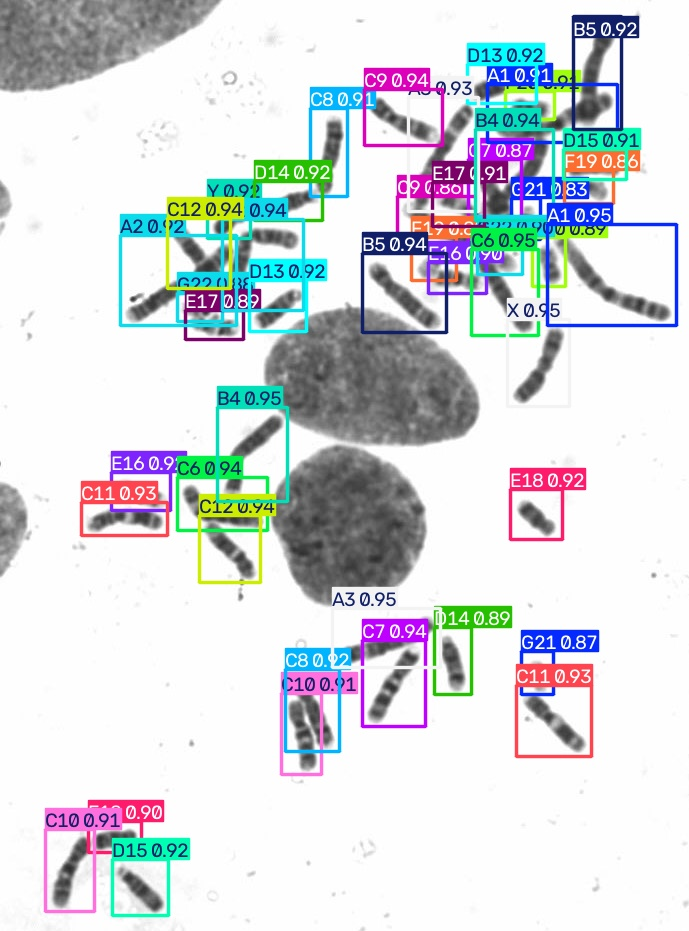

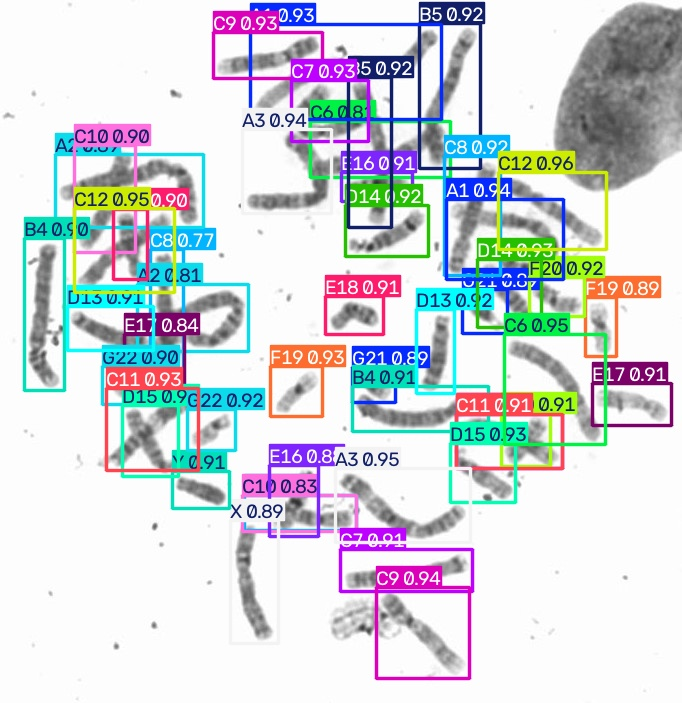

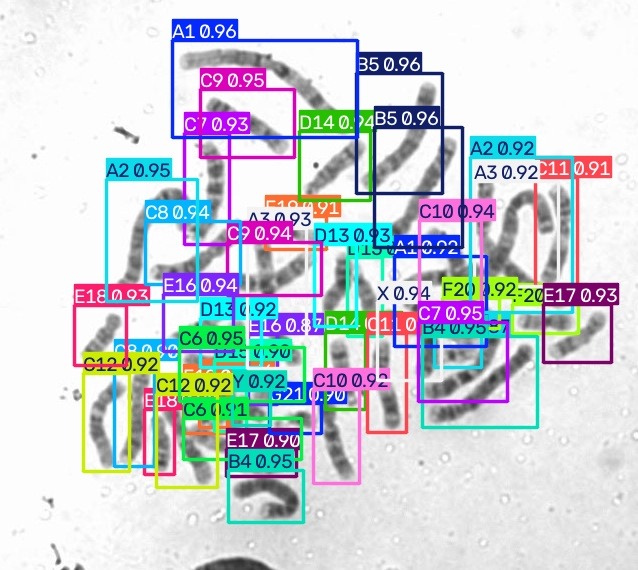

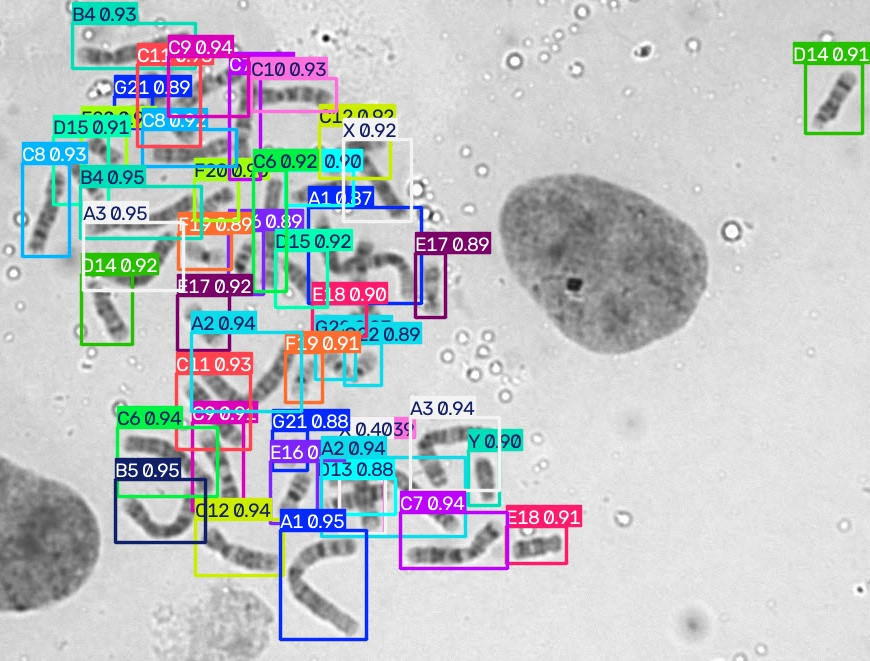

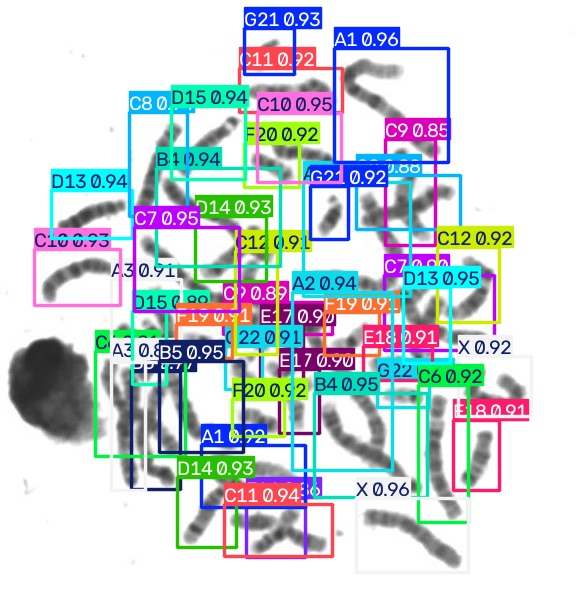

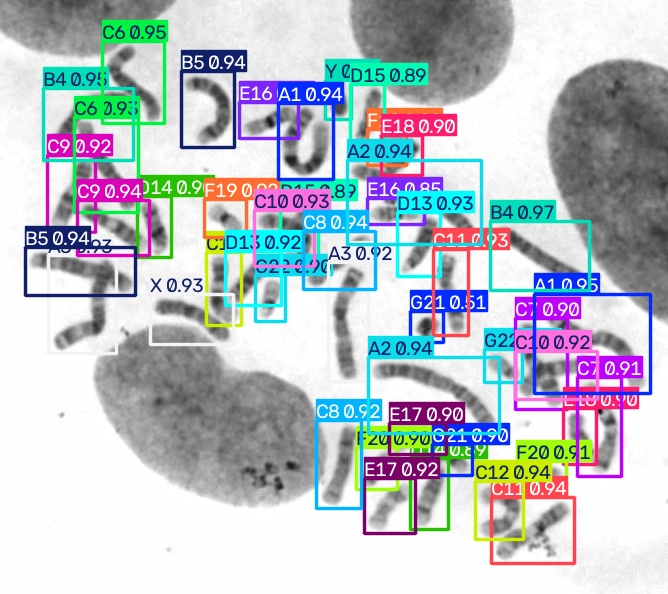

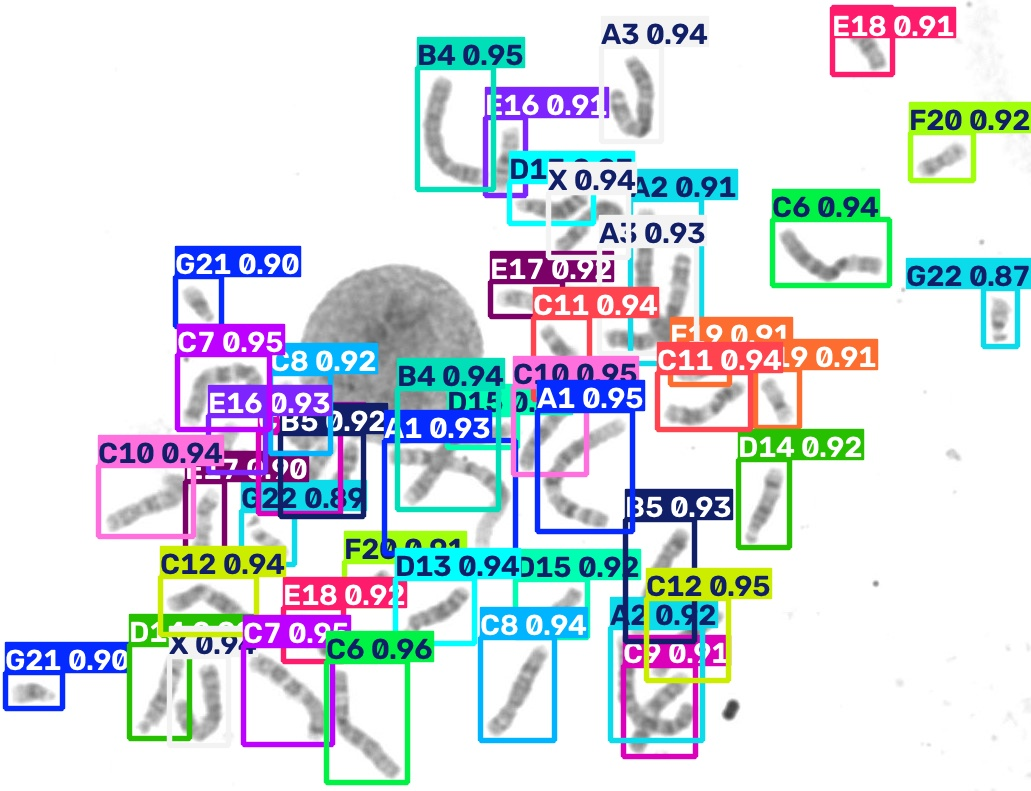

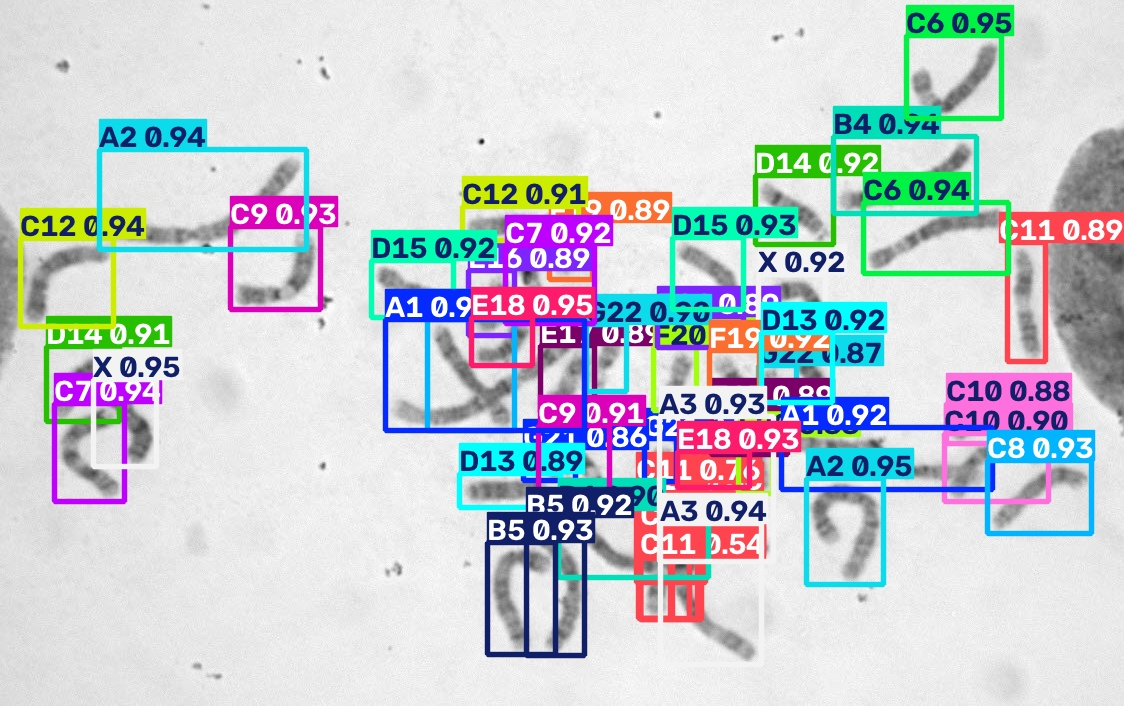

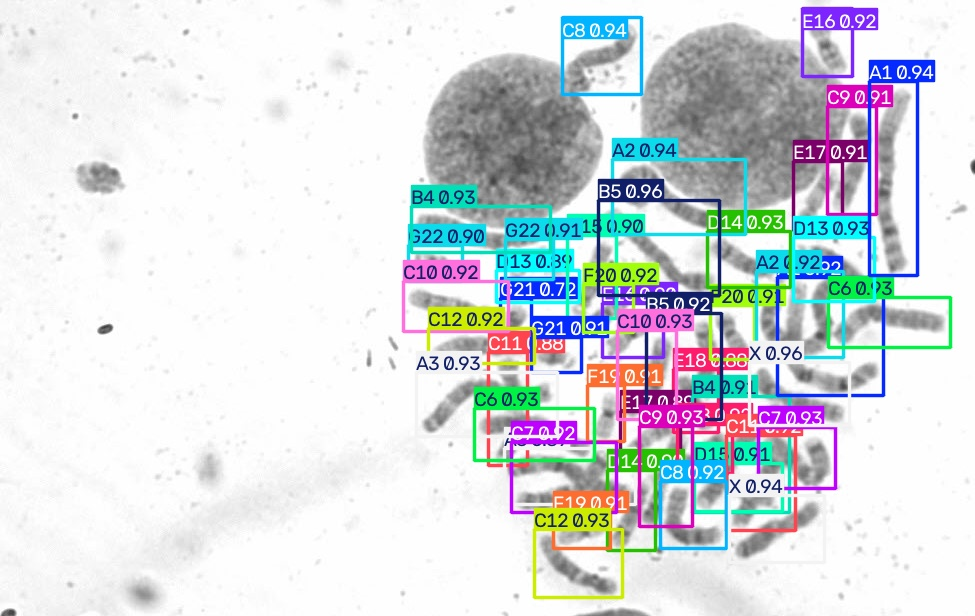

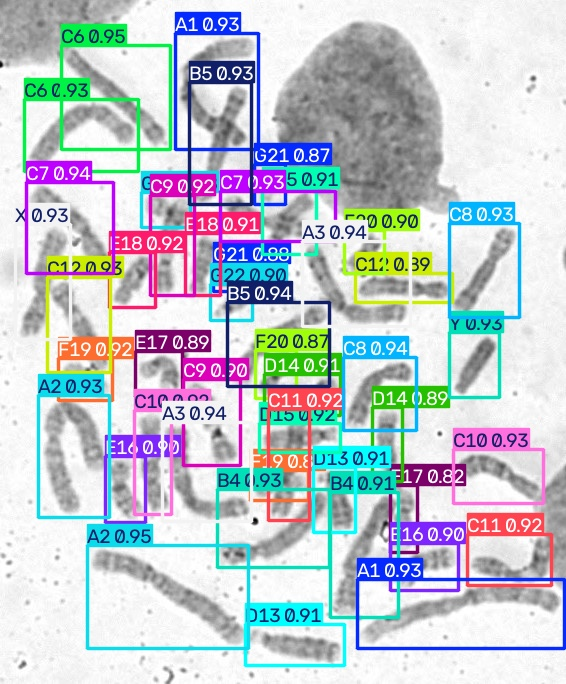

In [ ]:
import glob
from IPython.display import Image, display
for image_path in glob.glob(f'/content/runs/detect/predict/*.jpg')[:10]:
  display(Image(filename=image_path, height=400))
  print('\n')


# 7.&nbsp; Descargar modelo y métricas

El código crea una carpeta llamada my_model, mueve los pesos del modelo a esa carpeta y les cambia el nombre de `best.pt` a `my_model.pt`. También agrega los resultados del entrenamiento para que puedas consultarlos más adelante. Luego, comprime la carpeta en `my_model.zip`.

In [ ]:
# Crear la carpeta "my_model" para almacenar los pesos del modelo y los resultados del entrenamiento
!mkdir /content/my_model
!cp /content/runs/detect/train/weights/best.pt /content/my_model/my_model.pt
!cp -r /content/runs/detect/train /content/my_model

# Comprimir en "my_model.zip"
%cd my_model
!zip /content/my_model.zip my_model.pt
!zip -r /content/my_model.zip train
%cd /content

/content/my_model
  adding: my_model.pt (deflated 8%)
  adding: train/ (stored 0%)
  adding: train/confusion_matrix_normalized.png (deflated 16%)
  adding: train/train_batch8430.jpg (deflated 9%)
  adding: train/BoxPR_curve.png (deflated 26%)
  adding: train/results.png (deflated 9%)
  adding: train/weights/ (stored 0%)
  adding: train/weights/last.pt (deflated 8%)
  adding: train/weights/best.pt (deflated 8%)
  adding: train/train_batch2.jpg (deflated 3%)
  adding: train/val_batch0_labels.jpg (deflated 10%)
  adding: train/train_batch1.jpg (deflated 4%)
  adding: train/val_batch2_labels.jpg (deflated 7%)
  adding: train/BoxF1_curve.png (deflated 14%)
  adding: train/confusion_matrix.png (deflated 13%)
  adding: train/val_batch1_labels.jpg (deflated 8%)
  adding: train/args.yaml (deflated 53%)
  adding: train/labels.jpg (deflated 35%)
  adding: train/BoxP_curve.png (deflated 21%)
  adding: train/results.csv (deflated 62%)
  adding: train/train_batch0.jpg (deflated 3%)
  adding: train/v

In [ ]:
from google.colab import files

files.download('/content/my_model.zip')